# PHYS 2550 - Homework 4

Run the cells from top to bottom. Figures are saved to `figures/`.

## Part 1 - Theory

In [1]:
# SETUP: Import the libraries

%matplotlib inline
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from IPython.display import display

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
SEED = 2550

### 1.1. Three distances

Here $x_B-x_A=(3,4)$ and $x_C-x_A=(1,-1)$.

| Pair | Euclidean | Manhattan | Cosine similarity |
|---|---|---|---|
| $(A,B)$ | $\sqrt{9+16}=5$ | $3+4=7$ | $50/(5\cdot10)=1$ |
| $(A,C)$ | $\sqrt{1+1}\approx1.41$ | $1+1=2$ | $24/(5\cdot5)=0.96$ |
| Closer to $A$ | $C$ | $C$ | $B$ |

For cosine similarity a larger value means the points are closer, so $B$ is the nearer neighbour by that measure.

### 1.2. Which one is physical?

Cosine similarity. Since $x_B=2x_A$, star $B$ has the same ratio of blue to red flux as $A$ and is just twice as bright, so it's the same type of star at a different distance. Cosine similarity only depends on the direction of the flux vector, which is exactly the thing that stays fixed when both fluxes are scaled by the same factor.

### 1.3. Is it a distance?

$d_{\cos}(A,B)=1-1=0$ even though $A\neq B$, so it fails $d(x,y)=0\iff x=y$. Any two points on the same ray from the origin end up at distance 0.

### 1.4. Mahalanobis

Both stars are $\sqrt2\approx1.41$ from the mean in Euclidean distance. Using $S^{-1}=\tfrac13\begin{pmatrix}2&-1\\-1&2\end{pmatrix}$,

$$D_M(p)=\sqrt{\tfrac13(2-1-1+2)}=\sqrt{2/3}\approx0.82,\qquad D_M(q)=\sqrt{\tfrac13(2+1+1+2)}=\sqrt2\approx1.41.$$

The eigenvectors of $S$ are $(1,1)$ with eigenvalue 3 and $(1,-1)$ with eigenvalue 1, so the population is an ellipse stretched along the diagonal. That's why the two distances disagree. Star $p$ sits along the long axis, where the population is spread out, while $q$ sits along the short axis, where very few stars get that far from the mean, so I would flag $q$. The Euclidean distance has no information about the shape of the population.

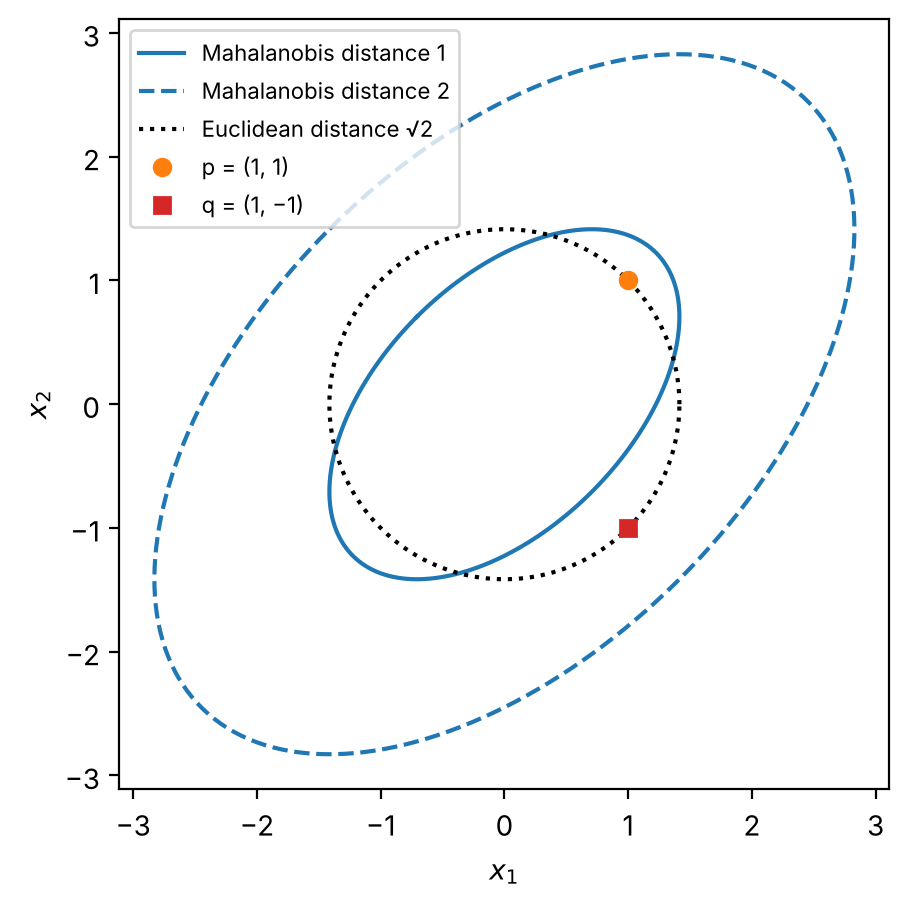

In [2]:
# PART 1.4: Sketch the star population with p and q

S = np.array([[2, 1], [1, 2]])
eigenvalues, eigenvectors = np.linalg.eigh(S)
t = np.linspace(0, 2 * np.pi, 200)
circle = np.stack([np.cos(t), np.sin(t)])

fig, ax = plt.subplots(figsize=(5, 5))
for n, style in [(1, "-"), (2, "--")]:
    contour = eigenvectors @ (n * np.sqrt(eigenvalues)[:, None] * circle)
    ax.plot(*contour, "C0" + style, label=f"Mahalanobis distance {n}")
ax.plot(*(np.sqrt(2) * circle), "k:", label="Euclidean distance √2")
ax.plot(1, 1, "o", color="C1", label="p = (1, 1)")
ax.plot(1, -1, "s", color="C3", label="q = (1, −1)")
ax.set(xlabel="$x_1$", ylabel="$x_2$", aspect="equal")
ax.legend(fontsize=8)
fig.savefig(FIG_DIR / "mahalanobis.png", dpi=150, bbox_inches="tight")
plt.show()

### 1.5. Outliers

The squared Euclidean distance is $1+1+1+100=103$, and the fourth coordinate contributes 100 of that, or 97%. For the Manhattan distance it contributes 10 out of 13, or 77%. Squaring turns a difference of 10 into 100, so one bad coordinate dominates the Euclidean distance much more than the Manhattan distance.

### 2.1. Iterations

| Step | Result |
|---|---|
| Assignment 1 | $C_1=\{x_1,x_3\}$, $C_2=\{x_2,x_4,x_5,x_6\}$, $J=0+1+0+25+32+34=92$ |
| Update 1 | $\mu_1=(0,0.5)$, $\mu_2=(3.5,3.25)$ |
| Assignment 2 | $C_1=\{x_1,x_2,x_3\}$, $C_2=\{x_4,x_5,x_6\}$, $J=1.75+6.9375=8.6875$ |
| Update 2 | $\mu_1=(\tfrac13,\tfrac13)$, $\mu_2=(\tfrac{13}3,\tfrac{13}3)$ |
| Assignment 3 | No change, $J=\tfrac43+\tfrac43=\tfrac83\approx2.67$ |

In the first assignment $x_4$, $x_5$ and $x_6$ all go to $\mu_2=(1,0)$, which is slightly closer to them (squared distances 25, 32 and 34, against 32, 41 and 41 for $\mu_1$). Nothing changes after the third assignment, and the final $J$ matches the $J_{\min}$ given for $k=2$.

### 2.2. $J$ never increases

In the assignment step every point moves to its nearest centroid, which can't make any term larger. In the update step the assignments are fixed and $J$ is a sum of quadratics in the $\mu_j$, each one minimised by the mean of its cluster. So $J$ goes down or stays the same at every step, and since there are only finitely many ways to assign the points the algorithm has to stop, although where it stops depends on the starting centroids and is only guaranteed to be a local minimum.

### 2.3. Initialisation

(i) Three of the five remaining points are in $\{x_4,x_5,x_6\}$, so $P=3/5$.

(ii) Measured from $x_1$, $D(x_i)^2=1,1,32,41,41$ for $i=2,\dots,6$. These add up to 116, so $P=(32+41+41)/116=57/58\approx0.98$.

(iii) $x_5$ and $x_6$ are tied as the farthest points, both at $D=\sqrt{41}$. Taking the lower index gives $x_5$, though either one is in the far group.

### 2.4. Evaluating the result

(i) With $a=(1+\sqrt2)/2\approx1.207$ and $b=(\sqrt{25}+\sqrt{32}+\sqrt{34})/3\approx5.496$, the silhouette is $s=(b-a)/b\approx0.78$. That's close to 1, which makes sense because $x_2$ is much closer to its own group than to the other one.

(ii) I took $\sigma_i$ to be the mean distance from a cluster's points to its centroid. By symmetry $\sigma_1=\sigma_2=(\sqrt2+2\sqrt5)/9\approx0.654$, and the centroids are $4\sqrt2\approx5.657$ apart, so $DB=2\sigma_1/d\approx0.23$. Low values mean tight clusters that are far apart, which describes these two groups well.

### 2.5. How many clusters?

$J_{\min}$ falls by about 48 going from one cluster to two, and after that each extra cluster lowers it by less than 1, so the elbow is at $k=2$. Minimising $J$ directly doesn't work because $J_{\min}$ keeps dropping as $k$ grows and reaches 0 at $k=n$, when every point has its own cluster.

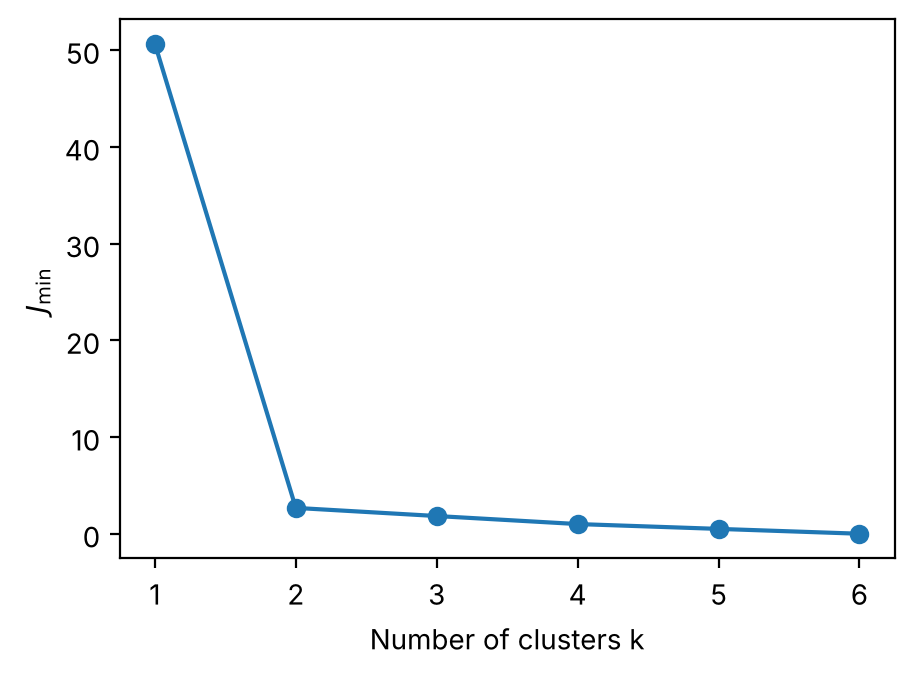

In [3]:
# PART 2.5: Plot the smallest J against k

k_values = np.arange(1, 7)
J_min = [50.67, 2.67, 1.83, 1.00, 0.50, 0]

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(k_values, J_min, "o-")
ax.set(xlabel="Number of clusters k", ylabel="$J_{\\min}$")
fig.savefig(FIG_DIR / "elbow.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.1-3.2. Single and complete linkage

In one dimension, single linkage just merges across the gaps between neighbouring hits (1, 2, 3, 1 and 5), smallest first. Complete linkage starts the same way with $\{0,1\}$ and $\{6,7\}$. The smallest distance after that is $d(\{0,1\},\{3\})=3$, compared with 4 from $\{3\}$ to $\{6,7\}$ and 6 from $\{6,7\}$ to $\{12\}$. Then $\{6,7\}$ joins $\{12\}$ at 6, which beats the 7 between $\{0,1,3\}$ and $\{6,7\}$.

| Step | Single linkage | Distance | Complete linkage | Distance |
|---|---|---|---|---|
| 1 | $\{0\}+\{1\}$ | 1 | $\{0\}+\{1\}$ | 1 |
| 2 | $\{6\}+\{7\}$ | 1 | $\{6\}+\{7\}$ | 1 |
| 3 | $\{0,1\}+\{3\}$ | 2 | $\{0,1\}+\{3\}$ | 3 |
| 4 | $\{0,1,3\}+\{6,7\}$ | 3 | $\{6,7\}+\{12\}$ | 6 |
| 5 | $\{0,1,3,6,7\}+\{12\}$ | 5 | $\{0,1,3\}+\{6,7,12\}$ | 12 |

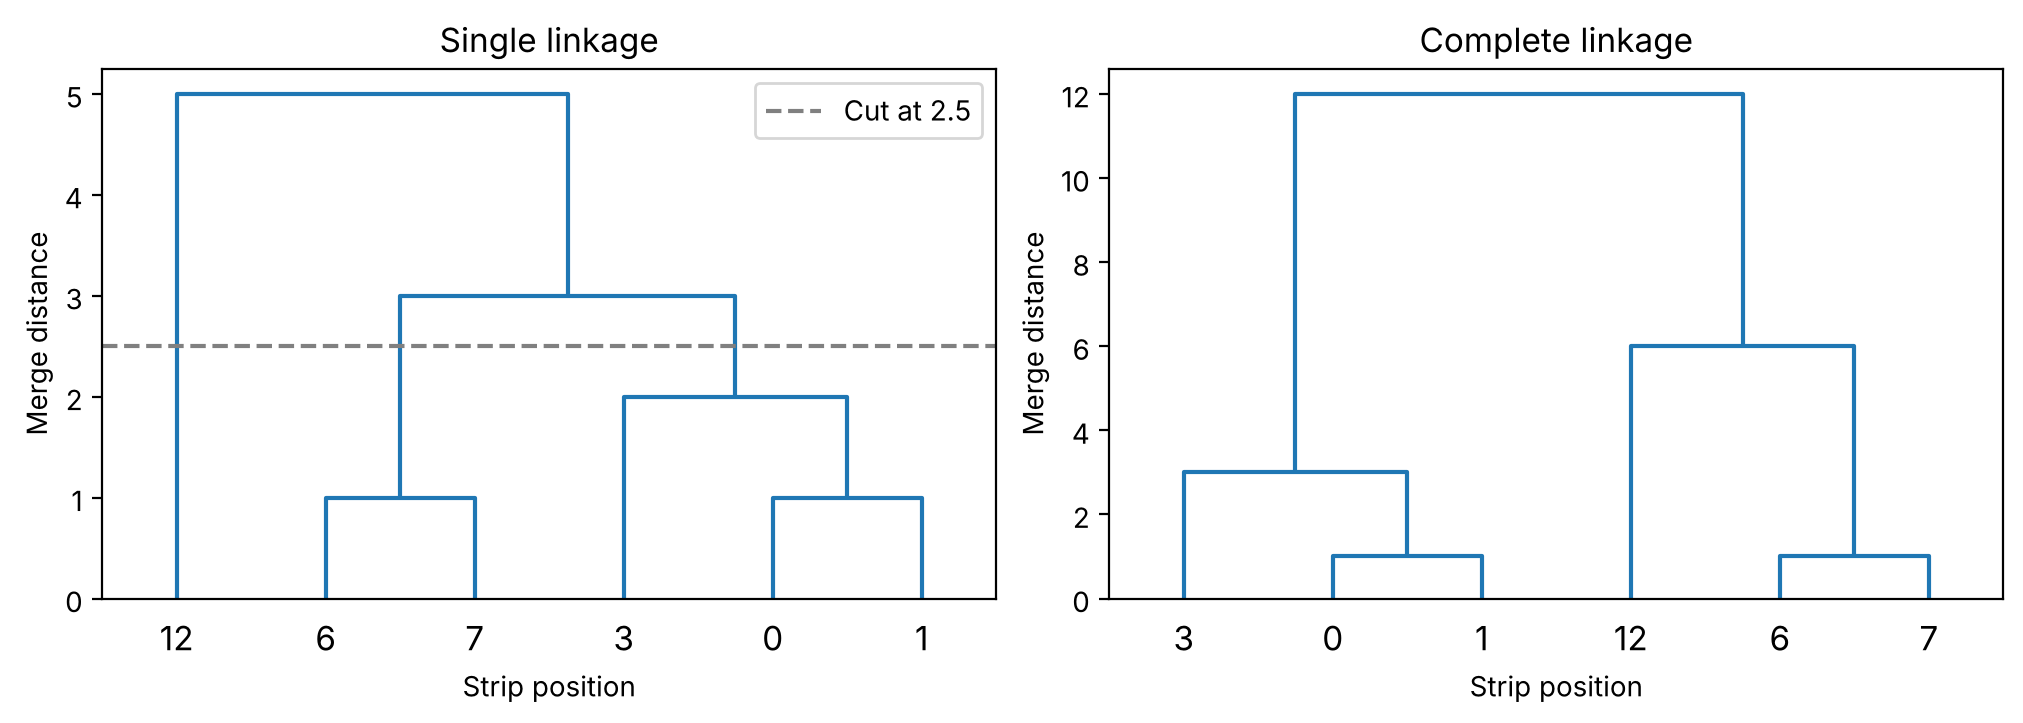

In [4]:
# PART 3.1-3.2: Draw the single- and complete-linkage dendrograms

hits = np.array([0, 1, 3, 6, 7, 12])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
for ax, method in zip(axes, ["single", "complete"]):
    dendrogram(linkage(hits[:, None], method=method), labels=hits, ax=ax, color_threshold=0)
    ax.set(title=f"{method.capitalize()} linkage", xlabel="Strip position", ylabel="Merge distance")
axes[0].axhline(2.5, color="gray", linestyle="--", label="Cut at 2.5")
axes[0].legend()
fig.savefig(FIG_DIR / "dendrograms.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.3. Two clusters, and one more hit

Cutting at two clusters gives $\{0,1,3,6,7\}$ and $\{12\}$ for single linkage, and $\{0,1,3\}$ and $\{6,7,12\}$ for complete linkage. Cutting the single-linkage tree at 2.5 leaves $\{0,1,3\}$, $\{6,7\}$ and $\{12\}$. The extra hit at 4.5 is 1.5 from both 3 and 6, so with it the same cut gives $\{0,1,3,4.5,6,7\}$ and $\{12\}$, and a single noise hit has merged two particle tracks. Single linkage only needs one close pair to join two clusters, so a chain of stray hits can connect clusters that are really separate.

### 3.4. DBSCAN: core, border, noise

Neighbour counts include the point itself (C is core, B is border, N is noise).

| $x$ | 0 | 1 | 2 | 3 | 5 | 8 | 9 | 10 | 14 |
|---|---|---|---|---|---|---|---|---|---|
| Neighbours | 2 | 3 | 3 | 2 | 1 | 2 | 3 | 2 | 1 |
| Label | B | C | C | B | N | B | C | B | N |

This gives two clusters, $\{0,1,2,3\}$ and $\{8,9,10\}$, with 5 and 14 left as noise.

### 3.5. Changing $R$

| $x$ | 0 | 1 | 2 | 3 | 5 | 8 | 9 | 10 | 14 |
|---|---|---|---|---|---|---|---|---|---|
| Neighbours | 3 | 4 | 4 | 4 | 2 | 3 | 3 | 3 | 1 |
| Label | C | C | C | C | B | C | C | C | N |

With the larger radius, 0, 3, 8 and 10 become core points and 5 is picked up as a border point of 3. The clusters grow to $\{0,1,2,3,5\}$ and $\{8,9,10\}$, but there are still two of them.

### 4.1. Same softmax

$$-\varepsilon\|x_i-\mu_j\|^2=-\varepsilon\|x_i\|^2+2\varepsilon\,x_i\cdot\mu_j-\varepsilon\|\mu_j\|^2.$$

The $-\varepsilon\|x_i\|^2$ term is the same for every $j$, so its exponential factors out of the numerator and the denominator and cancels. If all the centroids have the same length, the $-\varepsilon\|\mu_j\|^2$ term cancels for the same reason, which leaves $w_{ij}=\operatorname{softmax}_j(2\varepsilon\,x_i\cdot\mu_j)$. Then $x_i$ plays the query, $\mu_j$ the key, and $2\varepsilon$ does the job of $1/\sqrt{d_k}$.

### 4.2. One point, two centroids

The squared distances are 1 to $\mu_1$ and 4 to $\mu_2$, so

$$w_1=\frac{1}{1+e^{-3}}=\frac1{1.05}\approx0.95,\qquad w_2=\frac{e^{-3}}{1+e^{-3}}\approx0.05.$$

As $\varepsilon\to\infty$ the weights go to $(1,0)$ and the point belongs entirely to its nearest centroid, which is the hard k-means from Problem 2. As $\varepsilon\to0$ they go to $(\tfrac12,\tfrac12)$.

### 4.3. The update step

The data points act as the values, since $\mu_j=\sum_i\tilde w_{ij}x_i$ with $\tilde w_{ij}=w_{ij}/\sum_{i'}w_{i'j}$. In attention the weights $a_{ij}$ are normalised over $j$, the same index that the sum in $z_i$ runs over. Soft k-means is different. Its weights are normalised over the clusters $j$, but the update sums over the points $i$, which is why it needs the extra division by $\sum_i w_{ij}$. Put another way, the update step is attention where each centroid acts as a query over all the points.

### 4.4. Attention weights as a similarity

Not directly. $A$ isn't symmetric ($a_{12}=0.2$ but $a_{21}=0.6$), and $a_{21}>a_{22}$ would mean particle 2 is more similar to particle 1 than to itself. Each row of $A$ is really a probability distribution over the other particles. Symmetrising gives

$$S=\tfrac12(A+A^T)=\begin{pmatrix}0.7&0.4&0.1\\0.4&0.3&0.1\\0.1&0.1&0.8\end{pmatrix},\qquad d_{12}=0.6,\quad d_{13}=d_{23}=0.9.$$

Particles 1 and 2 are the closest pair, so single linkage merges them first and the two clusters are $\{1,2\}$ and $\{3\}$.

## Part 2 - Asteroid families

### Setup

After the cuts given in the problem there are 33,156 asteroids left.

In [5]:
# PART 5: Load the SDSS asteroid catalogue

url = ("https://raw.githubusercontent.com/astroML/"
       "astroML-data/main/datasets/ADR3.dat.gz")
cols = {19: "u", 21: "g", 23: "r", 25: "i", 27: "z", 29: "astar",
        33: "ast_flag", 36: "det_count", 57: "a", 58: "e", 59: "sini"}
raw = pd.read_csv(url, sep=r"\s+", header=None, usecols=list(cols))
raw = raw.rename(columns=cols)
df = raw[(raw.ast_flag == 1) & (raw.det_count == 1)]
df = df[(df.a > 0) & (df.astar > -0.3) & (df.astar < 0.4)
        & (df.i - df.z > -0.8) & (df.i - df.z < 0.6)].reset_index(drop=True)
print("Asteroids:", len(df))

Asteroids: 33156


### 5.1. Look at the data

The histogram of $a$ has three main groups with sharp gaps at about 2.50, 2.82 and 2.95 AU, which are the Kirkwood gaps at the 3:1, 5:2 and 7:3 resonances with Jupiter. The belt runs from about 2.1 to 3.25 AU, with a thin group further out at 3.3–3.6 AU. Both scatter plots also have tight clumps sitting on top of the smooth background, for example around $(a,\sin i)\approx(2.9,0.04)$, $(3.0,0.17)$ and $(3.15,0.02)$. The colour changes across the belt as well, from mostly $a^*>0$ on the inside to mostly $a^*<0$ further out, and each clump tends to be a single colour.

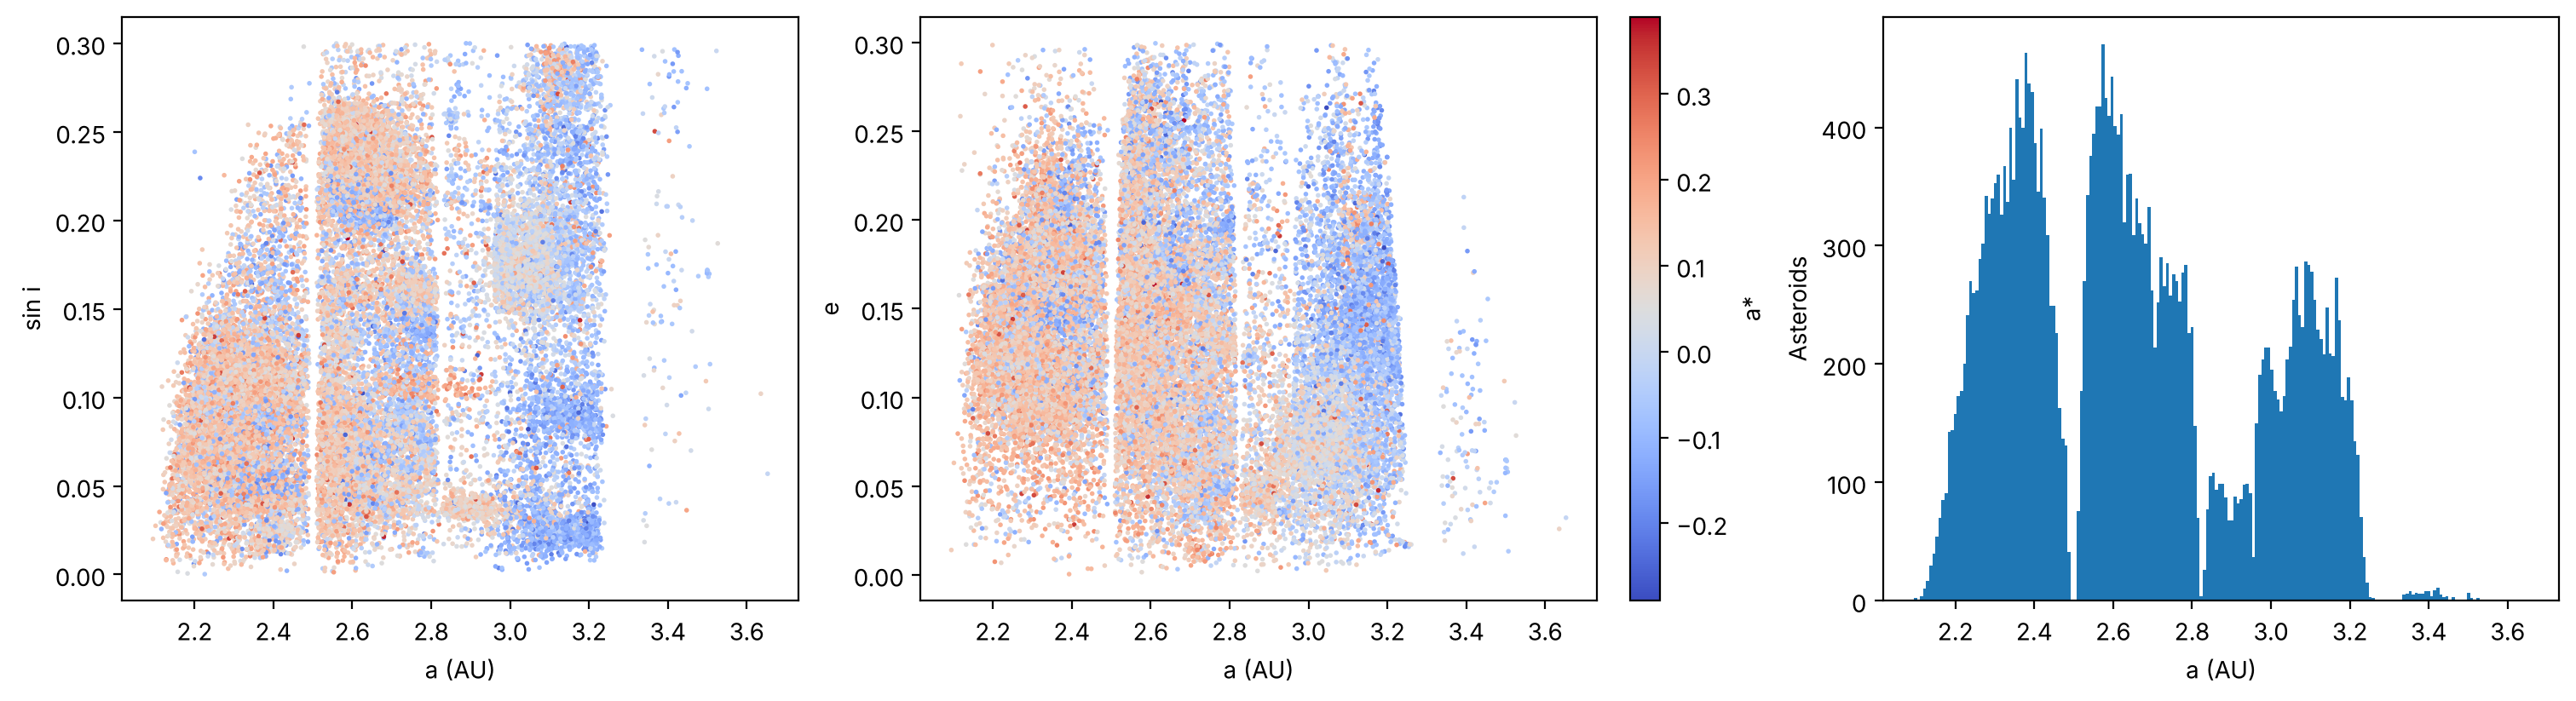

In [6]:
# PART 5.1: Plot the orbital elements coloured by a*

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, y, label in zip(axes[:2], ["sini", "e"], ["sin i", "e"]):
    points = ax.scatter(df.a, df[y], c=df.astar, s=1, cmap="coolwarm")
    ax.set(xlabel="a (AU)", ylabel=label)
fig.colorbar(points, ax=axes[1], label="a*")
axes[2].hist(df.a, bins=200)
axes[2].set(xlabel="a (AU)", ylabel="Asteroids")
fig.savefig(FIG_DIR / "data.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.2. Preprocessing

The standard deviations are 0.301 AU for $a$, 0.0575 for $e$ and 0.0730 for $\sin i$. Since $a$ is spread out four to five times more than the other two, it would dominate the raw Euclidean distance, and the clustering would mostly slice the belt along $a$ while ignoring the clumps in $e$ and $\sin i$. Standardising puts all three features on the same scale. That is still a choice about how much each one should count, and nothing physical fixes it.

In [7]:
# PART 5.2: Standardise the three orbital elements

features = df[["a", "e", "sini"]]
print(features.std())
X = StandardScaler().fit_transform(features)

a       0.300652
e       0.057482
sini    0.073030
dtype: float64


### 5.3. k-means

| $k$ | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|---|---|---|---|---|---|---|---|---|---|
| Inertia | 66,226 | 48,726 | 39,910 | 32,714 | 28,181 | 24,260 | 21,733 | 20,177 | 18,579 |
| Silhouette | 0.329 | 0.345 | 0.339 | 0.312 | 0.329 | 0.345 | 0.352 | 0.337 | 0.336 |

There's no sharp elbow in the inertia. The biggest drop is from $k=2$ to 3 (26%), and after that each extra cluster takes off between 7% and 18%. The silhouette barely moves either, staying between 0.31 and 0.35, so none of these clusterings are cleanly separated. I went with $k=3$ because it comes right after the biggest drop and its silhouette (0.345) is within 0.007 of the best one, at $k=8$. In the plot the three clusters are roughly the low-inclination inner belt, everything with $\sin i$ above about 0.15, and the low-inclination middle and outer belt, with the boundaries running straight through the clumps from 5.1.

For the comparison of initialisations I ran each method ten times with `n_init=1`:

| Initialisation | Mean inertia | Inertia range | Mean iterations | Iteration range |
|---|---|---|---|---|
| Random | $49,441\pm1,507$ | 48,725–52,300 | 14.3 | 8–32 |
| k-means++ | $48,726\pm0.4$ | 48,725–48,727 | 17.7 | 8–42 |

Random initialisation got stuck in a worse local minimum (inertia 52,300) in 2 of the 10 runs, while k-means++ ended up at essentially the same inertia every time. It didn't converge any faster, though, averaging 17.7 iterations against 14.3, so here the gain from k-means++ was consistency.

,k,inertia,silhouette
0,2,66225.626687,0.329295
1,3,48725.517877,0.344849
2,4,39909.676093,0.339106
3,5,32713.844895,0.312251
4,6,28181.132325,0.328706
5,7,24259.703154,0.344672
6,8,21733.147540,0.351660
7,9,20177.176586,0.337126
8,10,18579.443323,0.335525


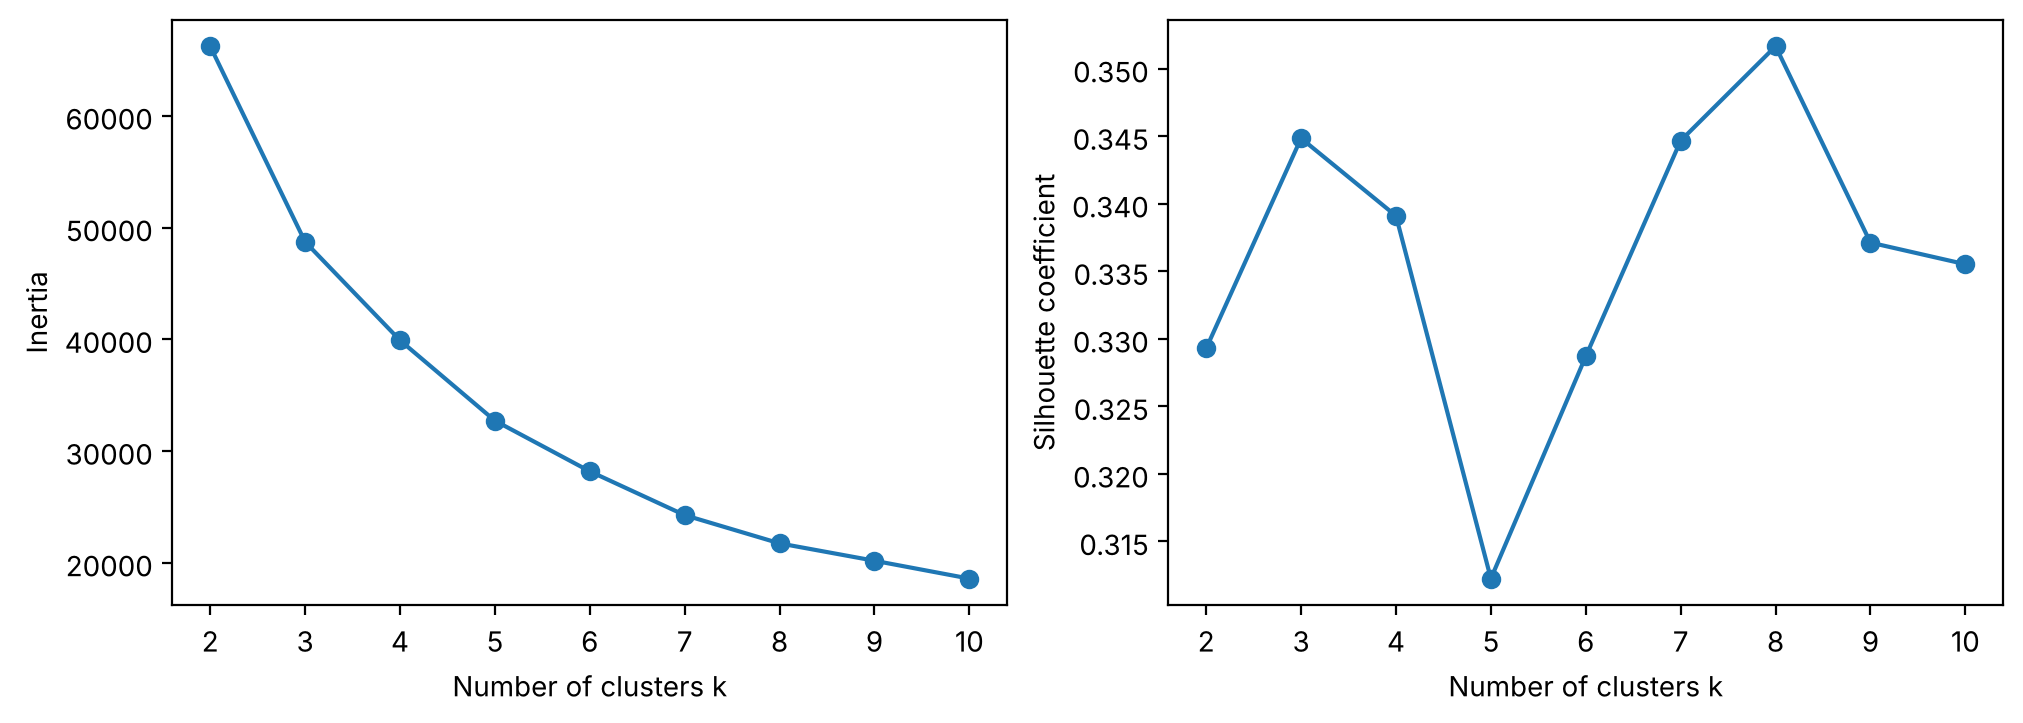

In [8]:
# PART 5.3: Inertia and silhouette coefficient for k = 2, ..., 10

ks = range(2, 11)
inertia, silhouette = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X, km.labels_, sample_size=5000, random_state=SEED))
display(pd.DataFrame({"k": ks, "inertia": inertia, "silhouette": silhouette}))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
axes[0].plot(ks, inertia, "o-")
axes[0].set(xlabel="Number of clusters k", ylabel="Inertia")
axes[1].plot(ks, silhouette, "o-")
axes[1].set(xlabel="Number of clusters k", ylabel="Silhouette coefficient")
fig.savefig(FIG_DIR / "kmeans-scan.png", dpi=150, bbox_inches="tight")
plt.show()

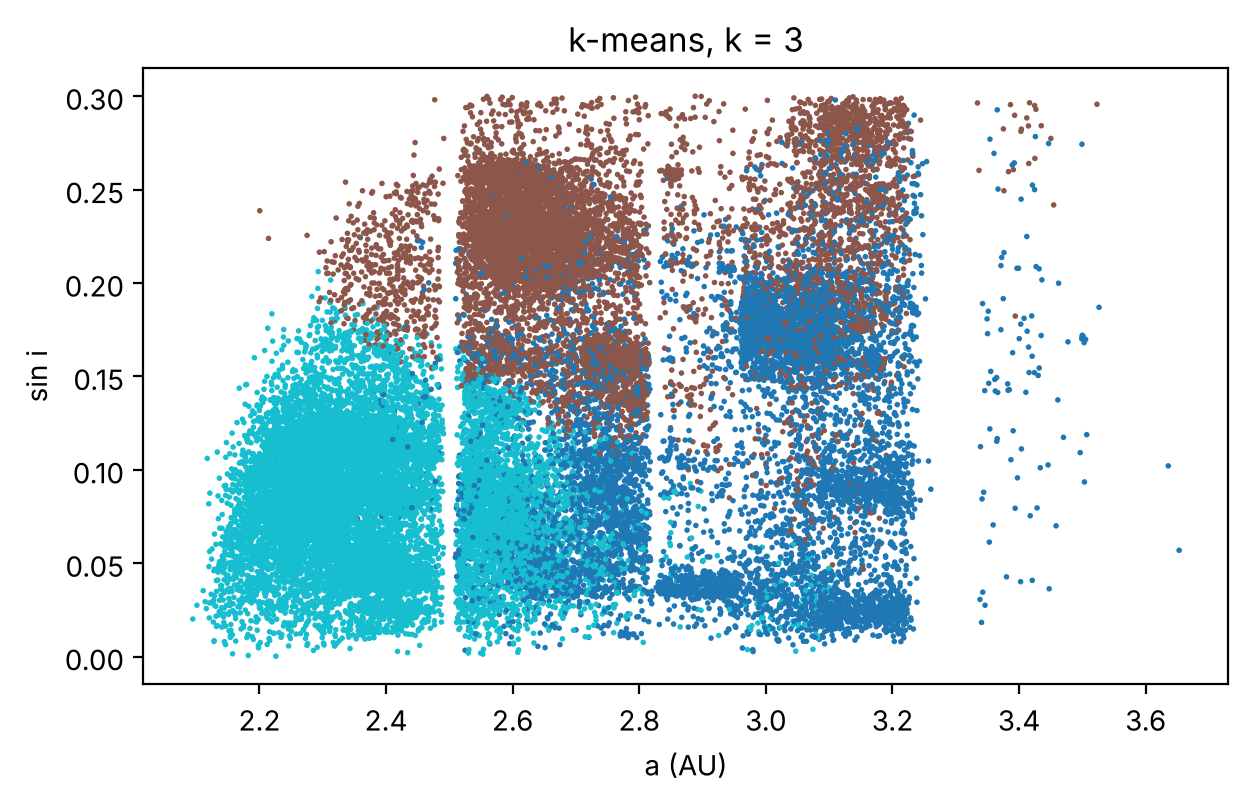

inertia                                          iterations  \
                  mean          std           min           max       mean   
init                                                                         
k-means++  48726.17837     0.365080  48725.484238  48726.699790       17.7   
random     49440.68978  1506.573159  48725.104964  52299.755469       14.3   

                             
                std min max  
init                         
k-means++  9.499123   8  42  
random     6.600505   8  32

In [9]:
# PART 5.3: Cluster with the chosen k and compare initialisations

k = 3
km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(df.a, df.sini, c=km.labels_, s=1, cmap="tab10")
ax.set(xlabel="a (AU)", ylabel="sin i", title=f"k-means, k = {k}")
fig.savefig(FIG_DIR / "kmeans-clusters.png", dpi=150, bbox_inches="tight")
plt.show()

runs = []
for init in ["random", "k-means++"]:
    for seed in range(10):
        m = KMeans(n_clusters=k, init=init, n_init=1, random_state=seed).fit(X)
        runs.append({"init": init, "seed": seed, "inertia": m.inertia_, "iterations": m.n_iter_})
runs = pd.DataFrame(runs)
display(runs.groupby("init")[["inertia", "iterations"]].agg(["mean", "std", "min", "max"]))

### 5.4. DBSCAN

| $R$ | 0.05 | 0.08 | 0.10 | 0.15 |
|---|---|---|---|---|
| Clusters | 21 | 39 | 42 | 28 |
| Noise fraction | 93.7% | 76.1% | 61.4% | 31.3% |

With $R=0.05$ or $0.08$ most of the points are labelled noise and only the densest cores survive. By $R=0.15$ the clusters have started merging, and the biggest one, with 9,516 members, covers most of the inner belt. I picked $R=0.10$, which gives the most clusters and still keeps the clumps from 5.1 apart. The cost is that 61% of the asteroids end up as noise, and the inner belt is still one large cluster of 6,055.

,R,clusters,noise fraction
0,0.05,21,0.936754
1,0.08,39,0.760828
2,0.10,42,0.613795
3,0.15,28,0.312915


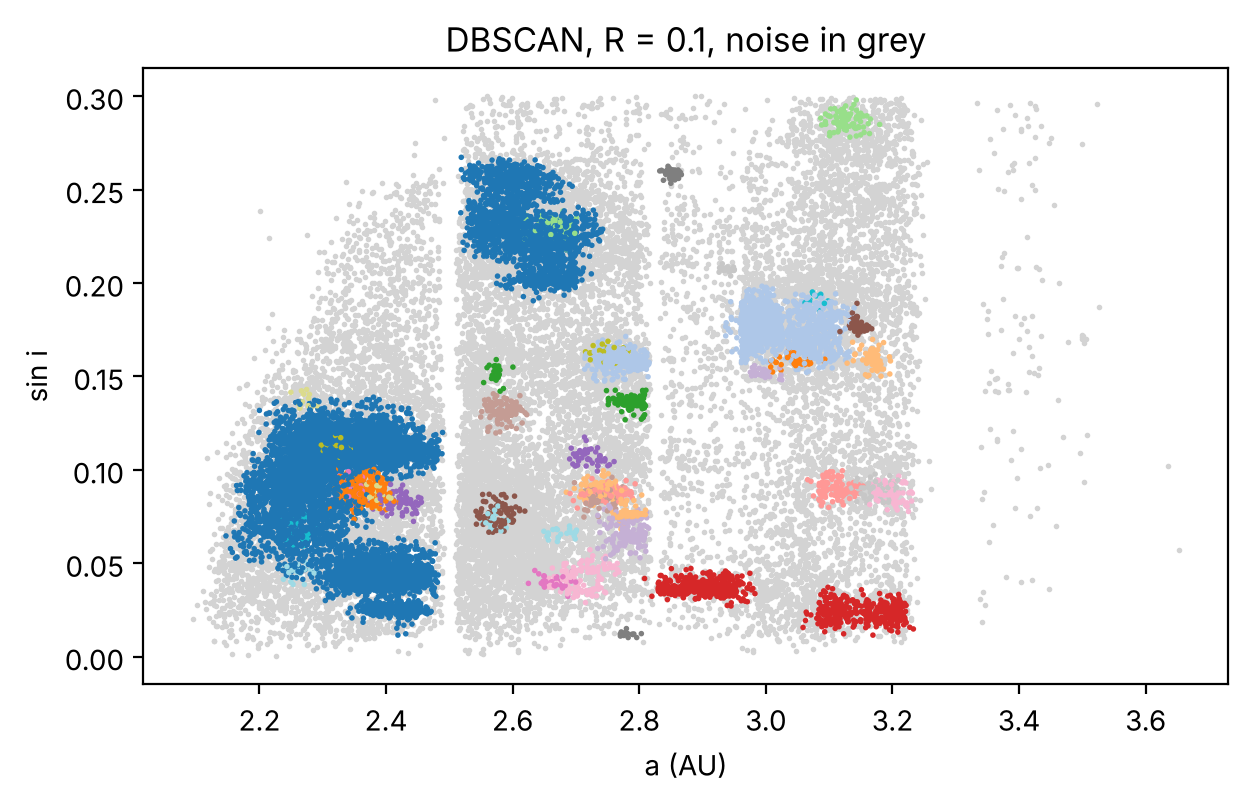

In [10]:
# PART 5.4: DBSCAN for several neighbourhood radii

scan = []
for R in [0.05, 0.08, 0.10, 0.15]:
    labels = DBSCAN(eps=R, min_samples=20).fit_predict(X)
    scan.append({"R": R, "clusters": labels.max() + 1, "noise fraction": np.mean(labels == -1)})
display(pd.DataFrame(scan))

R = 0.10
db = DBSCAN(eps=R, min_samples=20).fit_predict(X)
noise = db == -1
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(df.a[noise], df.sini[noise], c="lightgray", s=1)
ax.scatter(df.a[~noise], df.sini[~noise], c=db[~noise], s=1, cmap="tab20")
ax.set(xlabel="a (AU)", ylabel="sin i", title=f"DBSCAN, R = {R}, noise in grey")
fig.savefig(FIG_DIR / "dbscan-clusters.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.5. A physical check

Over the whole sample the standard deviation of $a^*$ is 0.107. For the clusters with at least 300 members:

| Algorithm | Clusters | Asteroids | Std of $a^*$ per cluster | Weighted std | Change |
|---|---|---|---|---|---|
| k-means | 3 | 33,156 | 0.100–0.110 | 0.104 | $-3%$ |
| DBSCAN | 7 | 10,458 | 0.049–0.100 | 0.083 | $-23%$ |

DBSCAN's groups are much more uniform in colour. Its five smaller clusters have standard deviations between 0.049 and 0.062, about half the value for the whole sample, while the k-means clusters are barely better than not clustering at all. Some of the DBSCAN clusters are known asteroid families. The darkest one, at $(a,\sin i)\approx(3.15,0.02)$ with mean $a^*=-0.113$, is the Themis family, and Koronis at (2.90, 0.04) and Eos at (3.02, 0.18) also come out as their own clusters. Fragments of one parent body are made of the same material, so a single-colour group is what a real family should look like, and the k-means clusters are better described as large regions of orbit space that each contain several families.

The comparison does favour DBSCAN in two ways. It has more clusters (7 against 3), which lowers the spread by itself, and it only counts the 31.5% of asteroids in its dense cores, since noise points are left out. Its two biggest clusters, with 6,055 and 1,524 members, have standard deviations of 0.093 and 0.100, close to k-means, probably because each one contains several families. A fairer test would run both methods on the same asteroids with a similar number of clusters.

Standard deviation of a* over all asteroids: 0.10735312634897774


,cluster,size,mean a*,std a*
0,0,9222,0.016423,0.103915
1,1,8902,0.042329,0.109959
2,2,15032,0.078926,0.100397


k-means size-weighted std of a*: 0.10394293031314192


,cluster,size,mean a*,std a*
0,0,1524,0.086266,0.100230
1,1,6055,0.090581,0.093015
2,2,377,0.108859,0.056780
3,3,1241,0.045141,0.053035
4,4,310,0.092194,0.061584
5,13,607,0.086079,0.050777
6,14,344,-0.112762,0.048962


DBSCAN size-weighted std of a*: 0.083183651976788


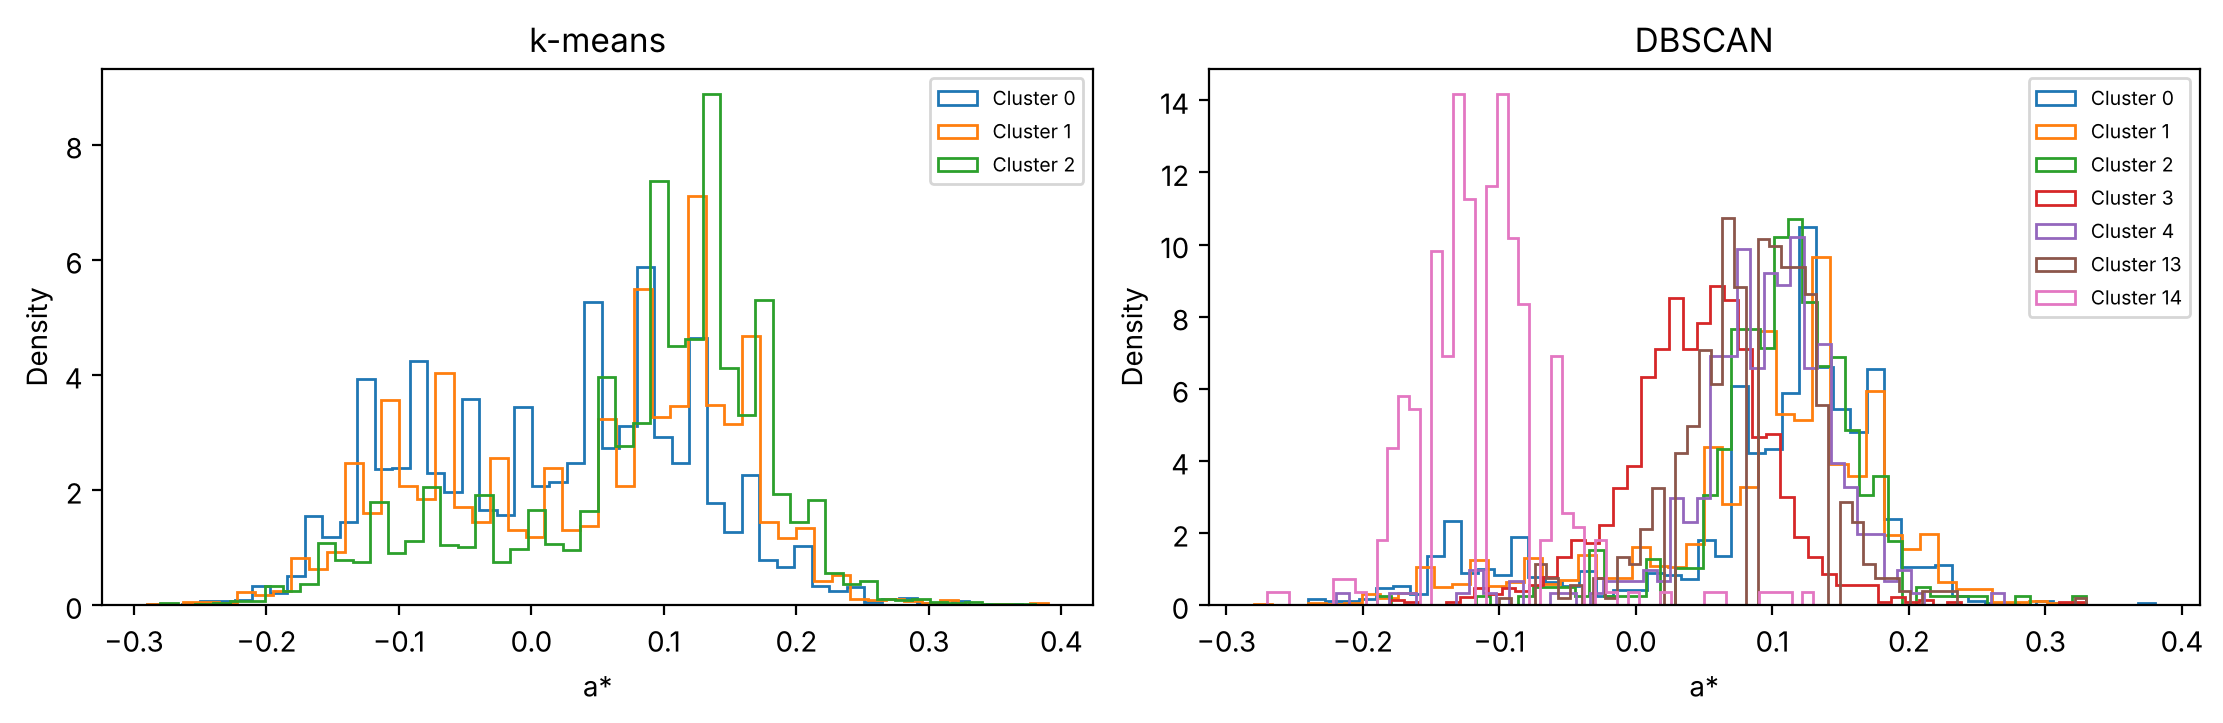

In [11]:
# PART 5.5: Compare the colour spread inside each cluster

print("Standard deviation of a* over all asteroids:", df.astar.std())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True)
for ax, (name, labels) in zip(axes, [("k-means", km.labels_), ("DBSCAN", db)]):
    rows = []
    for c in sorted(set(labels) - {-1}):
        astar = df.astar[labels == c]
        if len(astar) >= 300:
            rows.append({"cluster": c, "size": len(astar), "mean a*": astar.mean(), "std a*": astar.std()})
            ax.hist(astar, bins=50, histtype="step", density=True, label=f"Cluster {c}")
    rows = pd.DataFrame(rows)
    display(rows)
    print(name, "size-weighted std of a*:", np.average(rows["std a*"], weights=rows["size"]))
    ax.set(xlabel="a*", ylabel="Density", title=name)
    ax.legend(fontsize=7)
fig.savefig(FIG_DIR / "colour-check.png", dpi=150, bbox_inches="tight")
plt.show()

# AI Usage

I used Claude for help with the theory, code and writing. The numbers come from running the notebook.